In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import matplotlib.pyplot as plt
import matplotlib as mpl
import jax.numpy as jnp

from jax import random, vmap, jit
from jax.lax import scan
from pathlib import Path

%config InlineBackend.figure_format='retina'

# $D=1$ Burgers equation and its pseudospectral discretisation

We consider the viscous Burgers equation with homogeneous Dirichlet boundary conditions

$$
\frac{\partial u}{\partial t} + \frac{\partial}{\partial x}\left(\frac{u^2}{2}\right) = \nu \frac{\partial^2 u}{\partial x^2}, \quad u(0,t)=u(1,t)=0, \quad u(x,0)=u_0(x).
$$

### Odd extension

The FFT assumes periodicity, but our boundary conditions are Dirichlet. Extend $u$ to $[-1, 1]$ as an odd function, $u(-x)=-u(x)$, and then periodically with period $2$. The extension is odd and has $u(0)=u(1)=0$, and the Burgers equation preserves oddness ($u$, $u_{xx}$ and $uu_x$ are odd, $u_x$ is even). The Dirichlet problem on $[0,1]$ is therefore the same as the periodic problem for odd functions, and we can use Fourier methods directly (see Trefethen, *Spectral Methods in MATLAB*, Ch. 3 and Ch. 10).

### Fourier differentiation

Take $N$ interior nodes $x_j = jh$, $h=\frac{1}{N+1}$, and $M=2(N+1)$ equispaced points on the period $[0,2)$. A grid function is $v_j=u_j$ for $j=1,\dots,N$, $v_0=v_{N+1}=0$ and $v_{M-j}=-u_j$. Its discrete Fourier transform is $\hat v_m$ and the wavenumbers are $k_m=\pi m$ (the period is $2$). Differentiation becomes multiplication,

$$
\widehat{\left(\frac{dv}{dx}\right)}_m = i k_m \hat v_m, \qquad \widehat{\left(\frac{d^2v}{dx^2}\right)}_m = -k_m^2 \hat{v}_m,
$$

where for odd derivatives the Nyquist mode $m=M/2$ is set to zero. The error of this derivative decays faster than any power of $h$ for smooth $u$ (spectral accuracy).

### Pseudospectral time stepping

In Fourier space the equation becomes

$$
\frac{d\hat v_m}{dt} = \underbrace{-\nu k_m^2}_{L_m} \hat v_m - \frac{i k_m}{2}\,\widehat{(v^2)}_m.
$$

The nonlinear term is *pseudospectral*: we square $v$ in physical space (after an inverse FFT) and transform back, which costs $O(M\log M)$ instead of the $O(M^2)$ convolution. To reduce aliasing errors we zero the highest third of the modes ($2/3$ rule).

The diffusion term is stiff ($|L_m|\sim \nu \pi^2 M^2$). The substitution $\hat w_m = e^{-L_m t}\hat v_m$ (*integrating factor*) removes it exactly, and the remaining nonlinear term is integrated with the classical RK4 scheme. With $E=e^{L\,\Delta t}$, $E_2=e^{L\,\Delta t/2}$ and $g(\hat v)$ the nonlinear term, one step is

$$
\begin{aligned}
a &= g(\hat v), & b &= g\left(E_2(\hat v + \tfrac{\Delta t}{2} a)\right),\\
c &= g\left(E_2\hat v + \tfrac{\Delta t}{2} b\right), & d &= g\left(E\hat v + \Delta t E_2 c\right),\\
\hat v^{n+1} &= E\hat v + \tfrac{\Delta t}{6}\left(E a + 2E_2(b+c) + d\right).
\end{aligned}
$$

FFT is used for efficiency, but similarly to FEM, pseudospectral method represents a solution as a series $u_{N}(x)=\sum_{|i| \leq \frac{N}{2}} u_i\psi_i(x)$ but $\psi_i(x)$ are complex exponentials. A couple of them are drawn below:

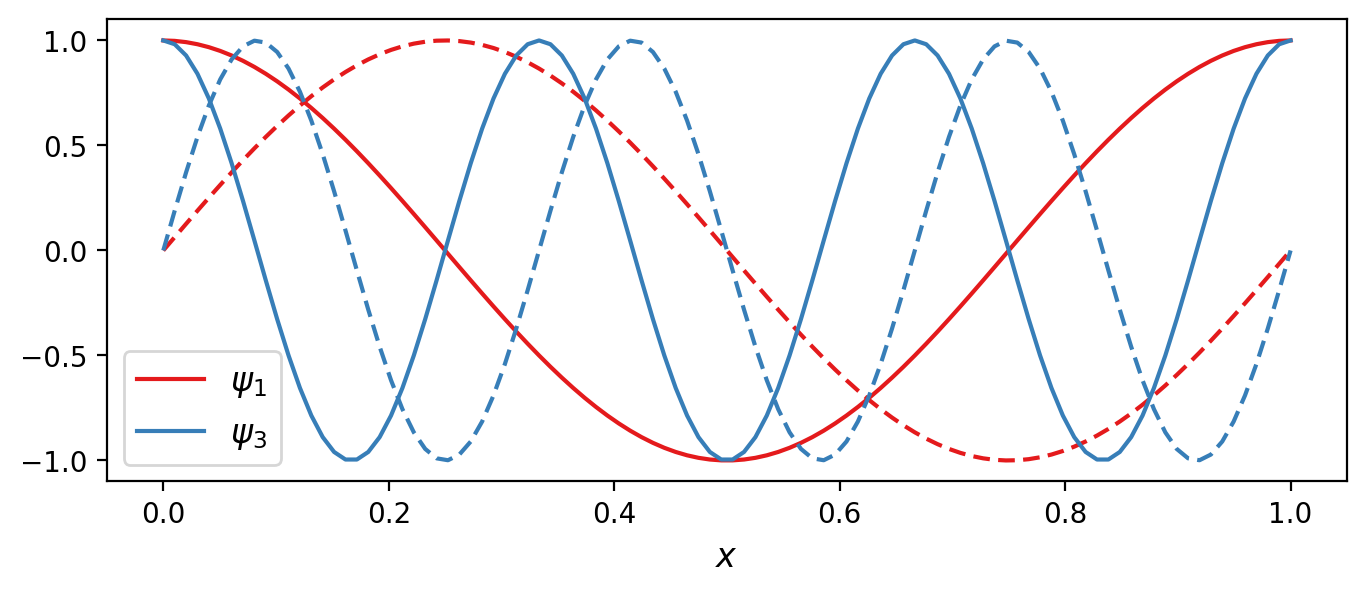

In [2]:
figure_name = "pseudospectral_basis"
if figure_name is not None:
    # the repository root is the closest parent of the working directory that contains `notebooks`
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks").is_dir())
    data_dir = root / "data"
    
    if not data_dir.exists():
        data_dir.mkdir()

colors = mpl.colormaps['Set1'].colors

def complex_exponential(x, freq):
    # i = 1, ..., N enumerates interior nodes x_i = i / (N+1)
    f = jnp.exp(1j*2*jnp.pi*freq*x)
    return f

N = 10
M = 100
x = jnp.linspace(0, 1, M)
freq = jnp.fft.fftfreq(N, d=1/N)

plt.figure(figsize=(8, 3))
for i, c in zip([1, 3], colors):
    plt.plot(x, jnp.real(complex_exponential(x, freq[i])), label=f"$\\psi_{{{i}}}$", color=c)
    plt.plot(x, jnp.imag(complex_exponential(x, freq[i])), dashes=[4, 2, 4, 2], color=c)
plt.xlabel("$x$", fontsize='large')
plt.legend(fontsize='large')

if figure_name is not None:
    plt.savefig(data_dir / f"{figure_name}.pdf", format='pdf', bbox_inches='tight');

In [3]:
def extend(u):
    # odd extension of the interior values to the periodic grid on [0, 2)
    return jnp.concatenate([jnp.zeros(1), u, jnp.zeros(1), -u[::-1]])

def solve_burgers(u0, nu=0.1, T=0.5, n_out=63, substeps=32):
    """Integrate Burgers from u0 (values at N interior nodes) up to T.

    Returns the solution at `n_out` equispaced times in (0, T], shape (n_out, N).
    """
    N = u0.shape[0]
    M = 2 * (N + 1)
    dt = T / (n_out * substeps)

    m = jnp.arange(M // 2 + 1)  # rfft wavenumber indices
    k = jnp.pi * m
    ik = 1j * k * (m != M // 2)  # zero Nyquist mode for odd derivatives
    mask = m < M / 3  # 2/3 dealiasing rule
    L = -nu * k**2
    E, E2 = jnp.exp(L * dt), jnp.exp(L * dt / 2)

    g = lambda v: -0.5 * ik * mask * jnp.fft.rfft(jnp.fft.irfft(v, n=M)**2)

    def step(v, _):  # integrating factor RK4
        a = g(v)
        b = g(E2 * (v + dt / 2 * a))
        c = g(E2 * v + dt / 2 * b)
        d = g(E * v + dt * E2 * c)
        return E * v + dt / 6 * (E * a + 2 * E2 * (b + c) + d), None

    def output(v, _):
        v, _ = scan(step, v, None, length=substeps)
        return v, jnp.fft.irfft(v, n=M)[1:N+1]

    return scan(output, jnp.fft.rfft(extend(u0)), None, length=n_out)[1]

### Sanity check

For $u_0 = 2\sin(\pi x) + \sin(3\pi x) - \sin(5\pi x)$ we compare solutions at $T=0.5$ for different $N$ with the one for $N=511$ (the grids are nested, since $N+1$ divides $512$). The error should decay faster than any power of $h$ until it hits the float32 round-off.

In [4]:
u0_fn = lambda x: 2 * jnp.sin(jnp.pi * x) + jnp.sin(3 * jnp.pi * x) - jnp.sin(5 * jnp.pi * x)

x_fine = jnp.linspace(0, 1, 513)[1:-1]
u_fine = solve_burgers(u0_fn(x_fine))[-1]
for N_ in [7, 15, 31, 63, 127, 255]:
    x_ = jnp.linspace(0, 1, N_ + 2)[1:-1]
    stride = 512 // (N_ + 1)
    error = jnp.max(jnp.abs(solve_burgers(u0_fn(x_))[-1] - u_fine[stride-1::stride]))
    print(f"N = {N_:3d}, error = {error:.2e}")

N =   7, error = 2.20e-02
N =  15, error = 7.17e-04
N =  31, error = 3.87e-07
N =  63, error = 2.38e-07
N = 127, error = 2.68e-07
N = 255, error = 2.38e-07


## Dataset of random Burgers problems

We generate random initial conditions: a random Fourier series with spectral weights $(1+\alpha k^2)^{-n}$, multiplied by $\sin(\pi x)$ to satisfy the boundary conditions. We take $\nu=0.1$ and $T=0.5$ as in the reference, and store the initial condition and the solution at $T$ at the $N=512$ interior nodes:

- `grid points`: shape `(N,)`;
- `initial condition`: shape `(N_samples, N)`;
- `solution`: shape `(N_samples, N)`.

In [5]:
def get_weights(N, n, alpha):
    w = jnp.fft.rfftfreq(N)
    return 1 / (1 + alpha * (2 * jnp.pi * w)**2)**n

def get_random_function(key, w, N):
    c = random.normal(key, (w.shape[0],), dtype=jnp.complex64) * w
    return jnp.fft.irfft(c, n=N)

def get_dataset(key, N_samples, N=512, nu=0.001, T=0.5):
    x = jnp.linspace(0, 1, N + 2)[1:-1]
    w = get_weights(N, 2, 200)

    def sample(key):
        u0 = get_random_function(key, w, N) * jnp.sqrt(N) * 5 * jnp.sin(jnp.pi * x)
        return u0, solve_burgers(u0, nu, T)[-1]

    u0, u = jit(vmap(sample))(random.split(key, N_samples))
    return {"grid points": x, "initial condition": u0, "solution": u}

{'grid points': (512,), 'initial condition': (1000, 512), 'solution': (1000, 512)}


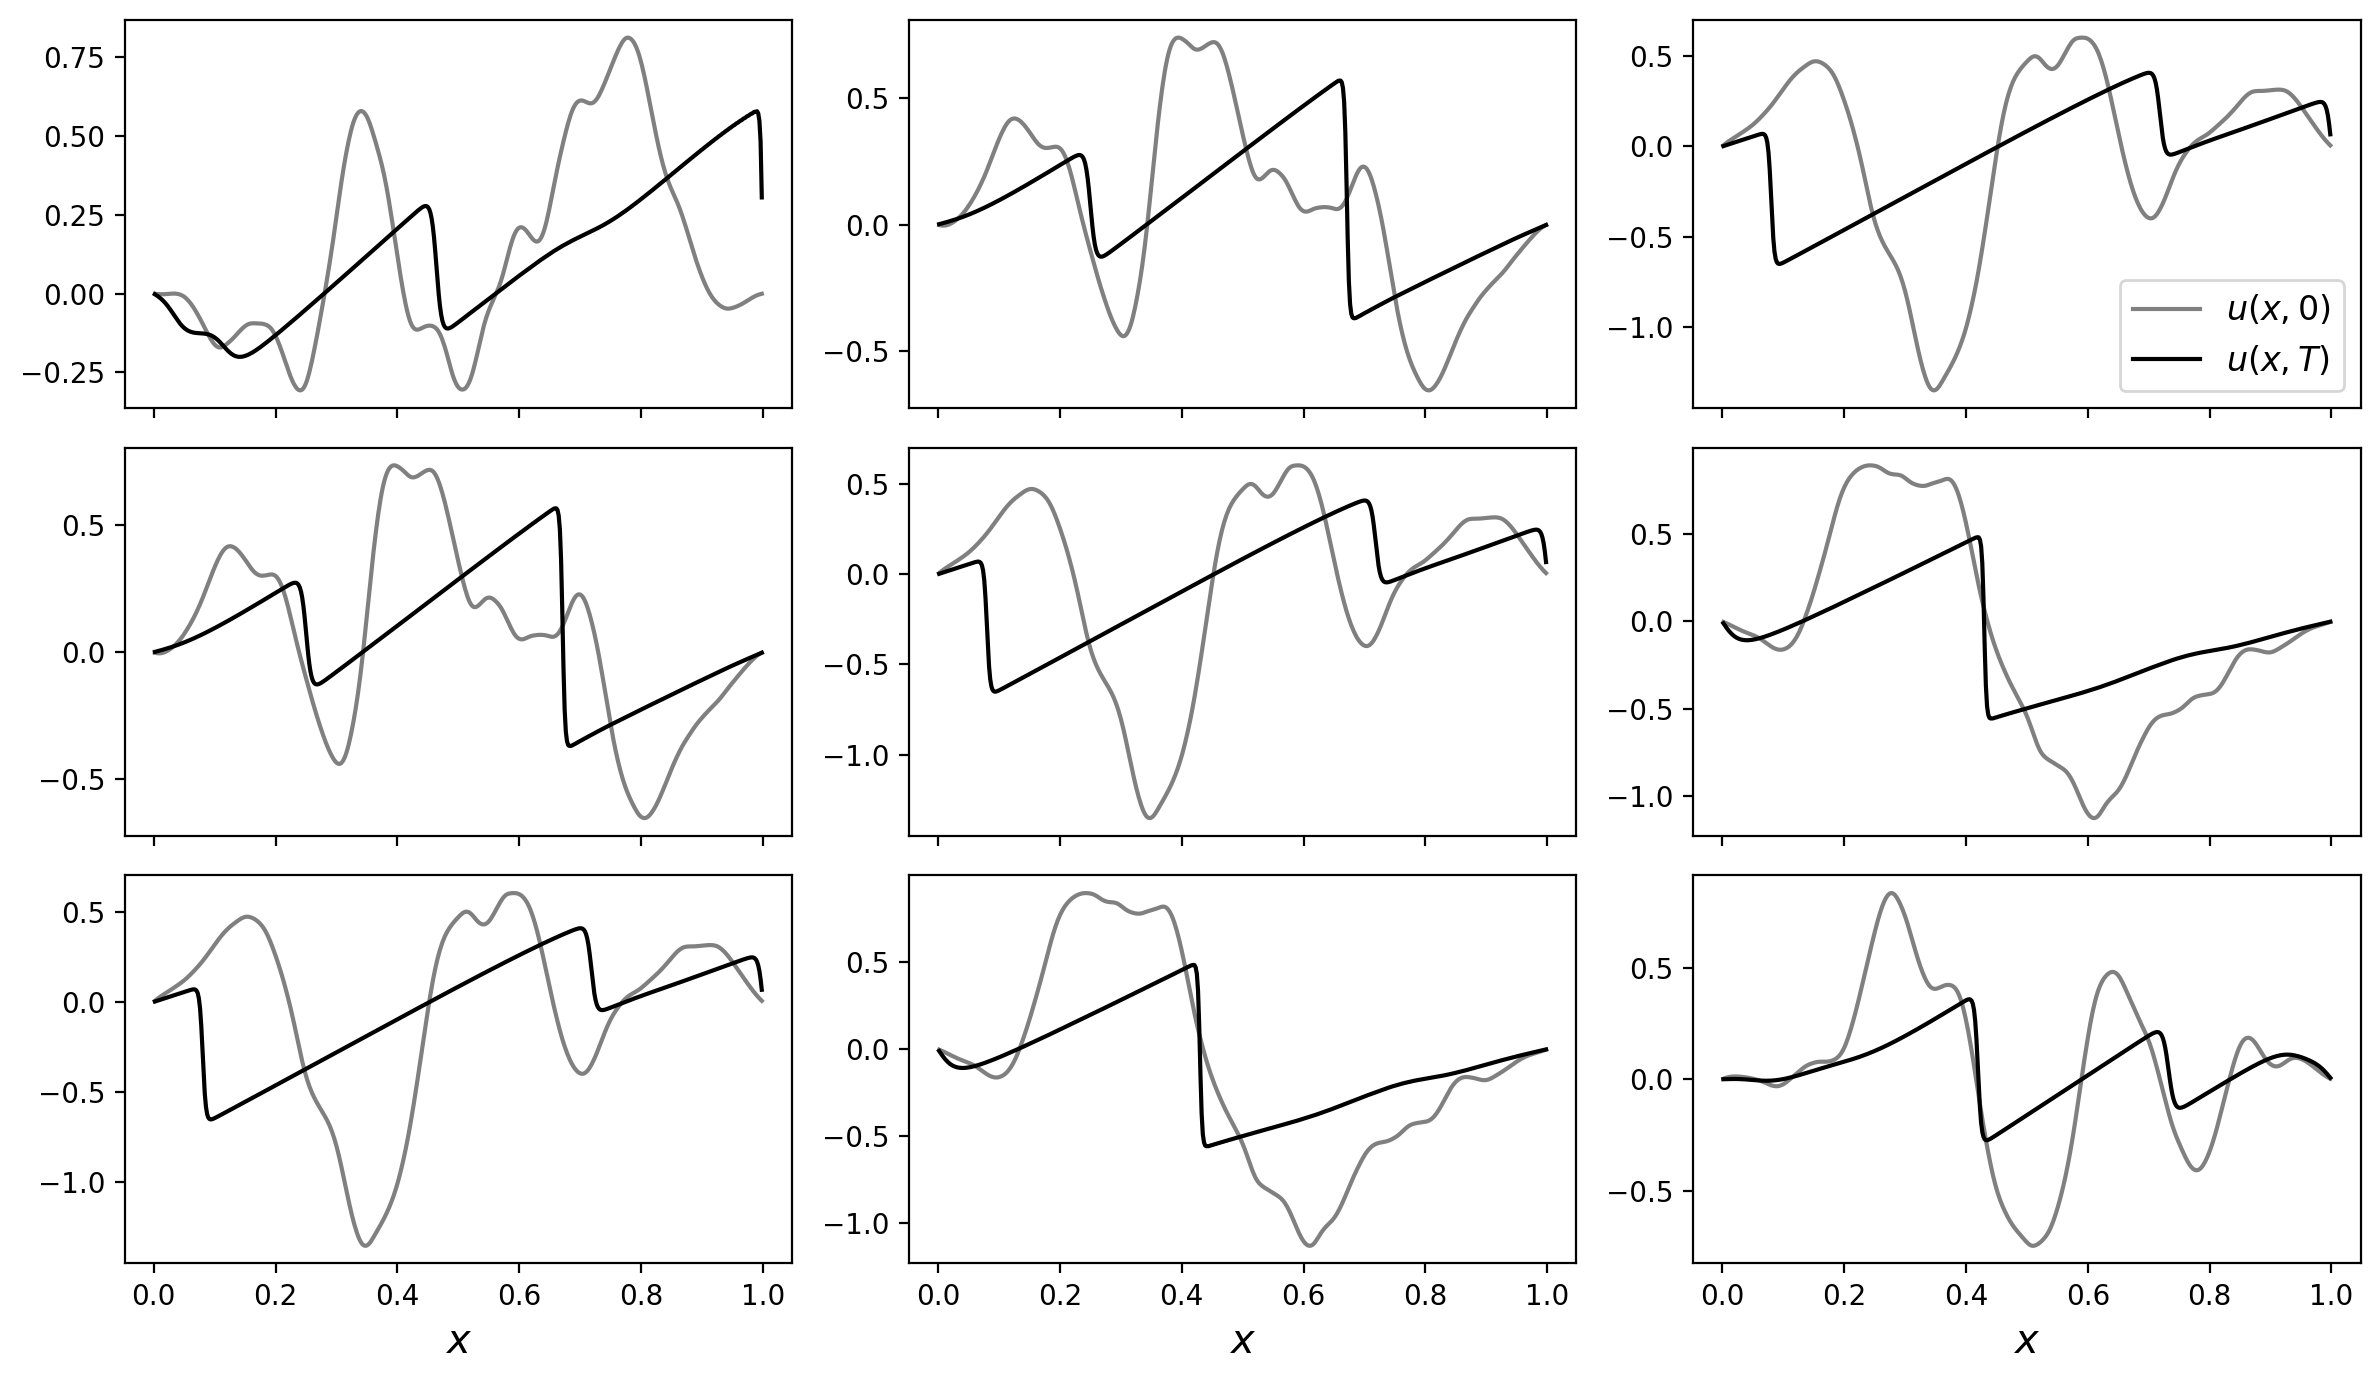

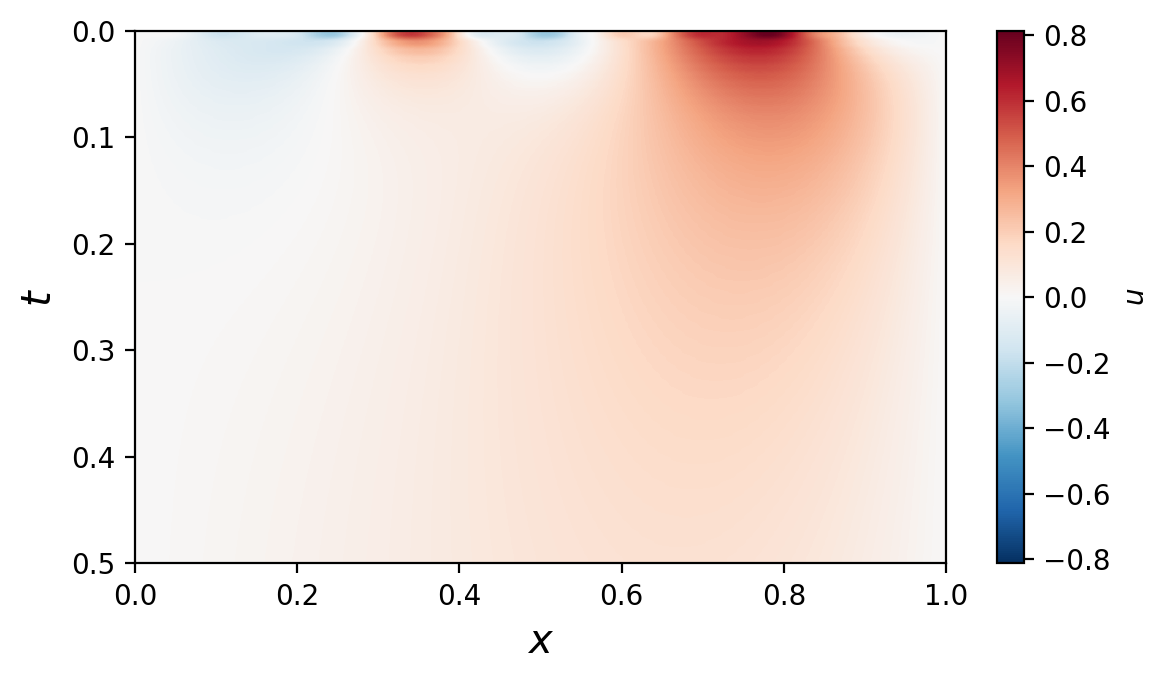

In [6]:
data = get_dataset(random.PRNGKey(67), 1000)
print({k: v.shape for k, v in data.items()})

fig, axes = plt.subplots(3, 3, figsize=(12, 7), sharex=True)
for j in range(3):
    for i, ax in enumerate(axes[j]):
        ax.plot(data["grid points"], data["initial condition"][j+i], color="gray", label="$u(x, 0)$")
        ax.plot(data["grid points"], data["solution"][j+i], color="black", label="$u(x, T)$")
        if j == 2:
            ax.set_xlabel("$x$", fontsize='x-large')
axes[0, 2].legend(fontsize='large')
plt.tight_layout();

figure_name = "Burgers_dataset"
if figure_name is not None:
    # the repository root is the closest parent of the working directory that contains `notebooks`
    root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks").is_dir())
    data_dir = root / "data"
    
    if not data_dir.exists():
        data_dir.mkdir()

    plt.savefig(data_dir / f"{figure_name}.pdf", format='pdf', bbox_inches='tight');

# space-time evolution of a single sample
x = data["grid points"]
U = solve_burgers(data["initial condition"][0])
U = jnp.concatenate([data["initial condition"][:1], U])
plt.figure(figsize=(6, 3.5))
plt.imshow(U, extent=[0, 1, 0.5, 0], aspect="auto", cmap="RdBu_r", vmin=-jnp.abs(U).max(), vmax=jnp.abs(U).max())
plt.colorbar(label="$u$")
plt.xlabel("$x$", fontsize='x-large')
plt.ylabel("$t$", fontsize='x-large')
plt.tight_layout();

## Saving the dataset

As before, we save the dataset to the folder `data` in the root of the repository (next to `notebooks`), creating it if necessary, so that it can be reused in the further tutorials.

In [7]:
# the repository root is the closest parent of the working directory that contains `notebooks`
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks").is_dir())
data_dir = root / "data"

if not data_dir.exists():
    data_dir.mkdir()
    print(f"Created {data_dir.relative_to(root)}")
else:
    print(f"{data_dir.relative_to(root)} already exists")

jnp.savez(data_dir / "burgers_dataset.npz", **data)
print(f"Saved dataset to {(data_dir / 'burgers_dataset.npz').relative_to(root)}")

data already exists
Saved dataset to data/burgers_dataset.npz
